In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [47]:
df = pd.read_csv(r"C:\Users\Ssanp\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 10000
Columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [48]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows:
0

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


In [49]:
# Remove identifier columns
df = df.drop(columns=["UDI", "Product ID"])

# Remove duplicate rows
df = df.drop_duplicates()

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (10000, 12)


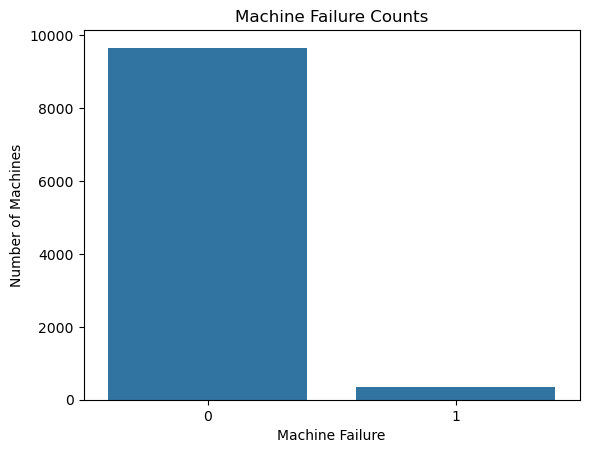

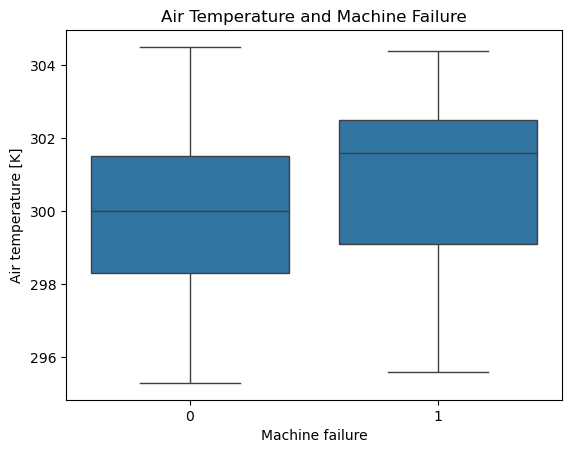

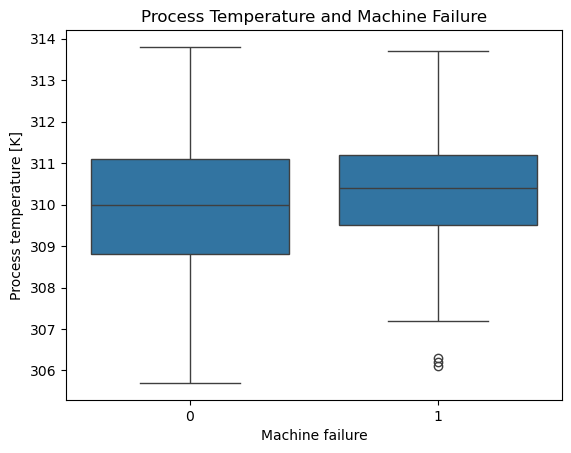

In [50]:
sns.countplot(x="Machine failure", data=df)

plt.title("Machine Failure Counts")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")
plt.show()

#machine failure vs air tempurature
sns.boxplot(x="Machine failure", y="Air temperature [K]", data=df)
plt.title("Air Temperature and Machine Failure")
plt.show()

#Machine Failure vs Process Temp
sns.boxplot(x="Machine failure", y="Process temperature [K]", data=df)
plt.title("Process Temperature and Machine Failure")
plt.show()

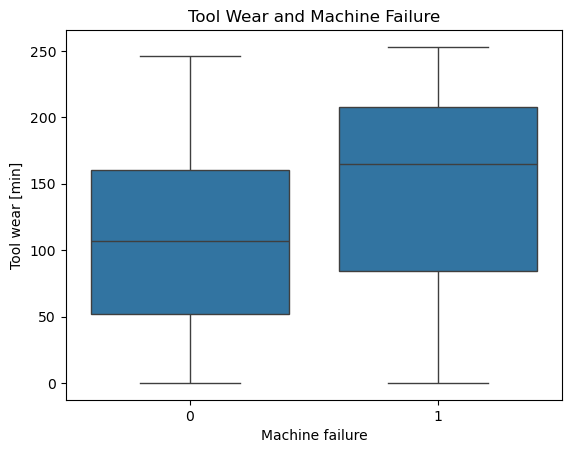

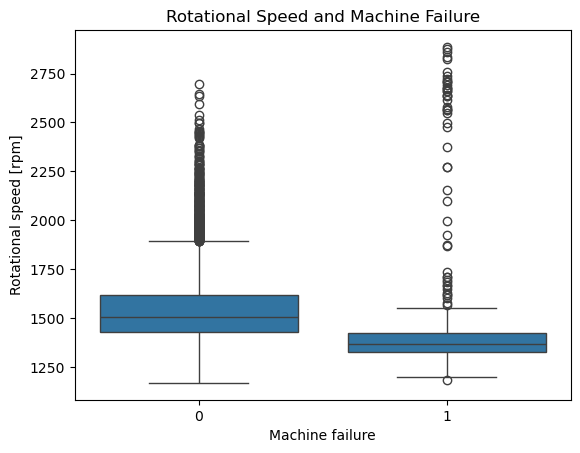

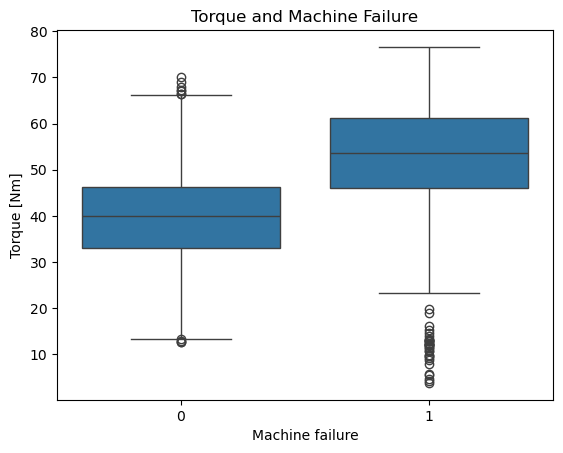

In [51]:
#machine failure x Tool weaer
sns.boxplot(x="Machine failure", y="Tool wear [min]", data=df)

plt.title("Tool Wear and Machine Failure")
plt.show()

#rotation speed x machine failure
sns.boxplot(x="Machine failure", y="Rotational speed [rpm]", data=df)

plt.title("Rotational Speed and Machine Failure")
plt.show()

#machine failure x torque
sns.boxplot(x="Machine failure", y="Torque [Nm]", data=df)

plt.title("Torque and Machine Failure")
plt.show()

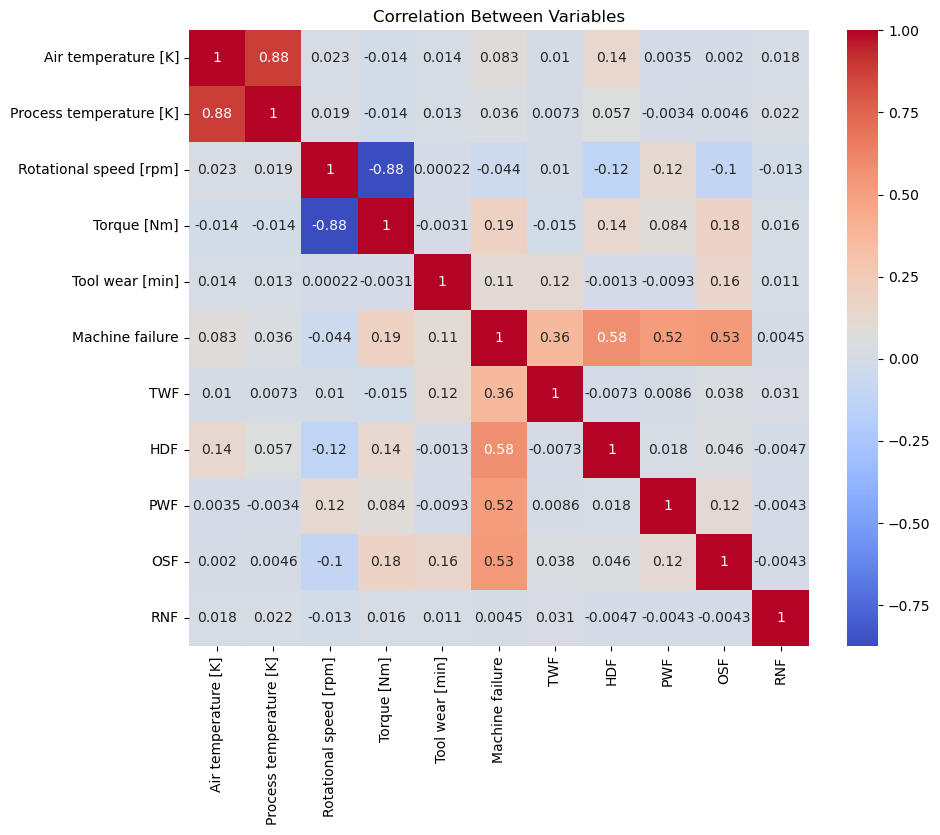

In [52]:
plt.figure(figsize=(10, 8))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Correlation Between Variables")
plt.show()

In [53]:
# Convert Type into numerical columns
df_model = pd.get_dummies(df, columns=["Type"], drop_first=True)

# Target variable
y = df_model["Machine failure"]

# Remove target and failure-specific columns
X = df_model.drop(columns=[
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
])

print("Number of features:", X.shape[1])
print("\nFeatures:")
print(X.columns.tolist())

Number of features: 7

Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']


In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


In [55]:
# Scale the data for Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model.fit(X_train_scaled, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test_scaled)

In [56]:
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)
logistic_recall = recall_score(y_test, logistic_predictions)
logistic_f1 = f1_score(y_test, logistic_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:  {logistic_accuracy:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"Recall:    {logistic_recall:.3f}")
print(f"F1 Score:  {logistic_f1:.3f}")

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy:  0.825
Precision: 0.142
Recall:    0.824
F1 Score:  0.242


In [57]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

In [58]:
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("---------------------")
print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1 Score:  {rf_f1:.3f}")

RANDOM FOREST RESULTS
---------------------
Accuracy:  0.981
Precision: 0.734
Recall:    0.691
F1 Score:  0.712


In [59]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.824,0.142,0.824,0.242
1,Random Forest,0.981,0.734,0.691,0.712


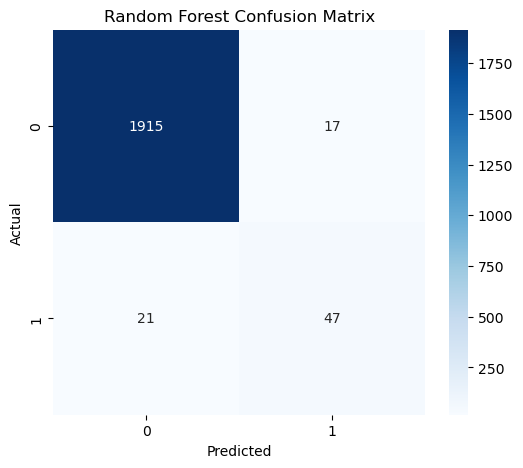

In [60]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [61]:
print("RANDOM FOREST CLASSIFICATION REPORT")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["No Failure", "Failure"]
    )
)

RANDOM FOREST CLASSIFICATION REPORT
-----------------------------------
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.73      0.69      0.71        68

    accuracy                           0.98      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [62]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(importance.round(4))

Feature Importance:
                   Feature  Importance
3              Torque [Nm]      0.3248
2   Rotational speed [rpm]      0.2836
4          Tool wear [min]      0.2141
0      Air temperature [K]      0.0973
1  Process temperature [K]      0.0650
5                   Type_L      0.0088
6                   Type_M      0.0065


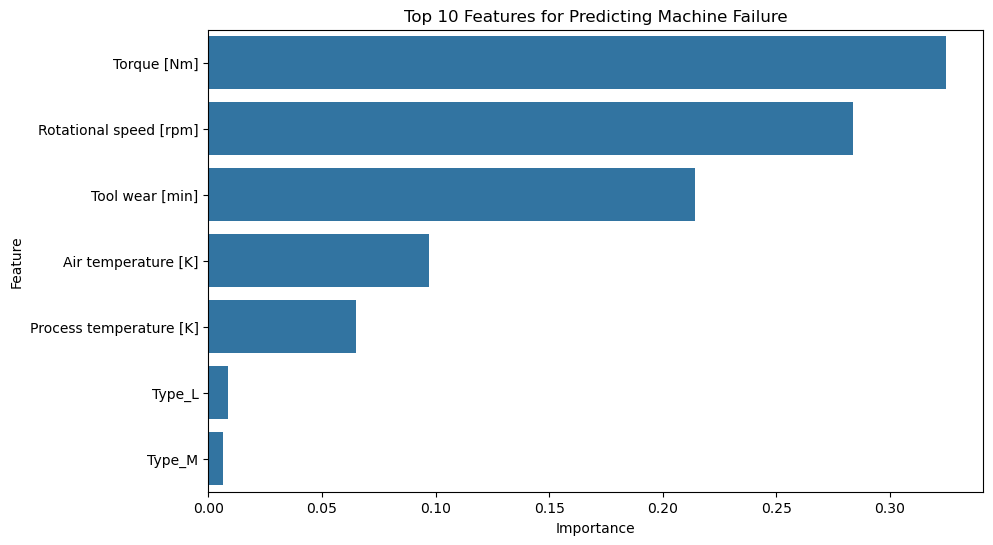

In [63]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance.head(10)
)

plt.title("Top 10 Features for Predicting Machine Failure")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [64]:
best_model = "Random Forest" if rf_f1 > logistic_f1 else "Logistic Regression"

print("====================================")
print("      FINAL PROJECT RESULTS")
print("====================================")

print("\nDataset")
print("-------")
print(f"Total rows: {len(df)}")
print(f"Total features used for modeling: {X.shape[1]}")

print("\nLogistic Regression")
print("-------------------")
print(f"Accuracy:  {logistic_accuracy:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"Recall:    {logistic_recall:.3f}")
print(f"F1 Score:  {logistic_f1:.3f}")

print("\nRandom Forest")
print("-------------")
print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1 Score:  {rf_f1:.3f}")

print("\nBest Model Based on F1 Score:")
print(best_model)

print("\nTop 5 Features:")
print(importance.head(5).round(4))

      FINAL PROJECT RESULTS

Dataset
-------
Total rows: 10000
Total features used for modeling: 7

Logistic Regression
-------------------
Accuracy:  0.825
Precision: 0.142
Recall:    0.824
F1 Score:  0.242

Random Forest
-------------
Accuracy:  0.981
Precision: 0.734
Recall:    0.691
F1 Score:  0.712

Best Model Based on F1 Score:
Random Forest

Top 5 Features:
                   Feature  Importance
3              Torque [Nm]      0.3248
2   Rotational speed [rpm]      0.2836
4          Tool wear [min]      0.2141
0      Air temperature [K]      0.0973
1  Process temperature [K]      0.0650
